In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_selection import f_classif, mutual_info_classif
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix


In [2]:
failure_data = pd.read_csv('/content/ai4i2020.csv')

In [3]:
failure_data.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [4]:
failure_data.sample(10)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
7553,7554,L54733,L,300.3,311.3,1505,39.6,107,0,0,0,0,0,0
2805,2806,L49985,L,300.0,309.4,1460,43.5,102,0,0,0,0,0,0
8036,8037,L55216,L,300.7,311.7,1460,46.1,15,0,0,0,0,0,0
3471,3472,L50651,L,301.8,310.7,1441,49.3,58,0,0,0,0,0,0
4922,4923,M19782,M,303.4,312.2,1615,35.7,56,0,0,0,0,0,0
9333,9334,L56513,L,298.5,309.0,1450,40.5,199,0,0,0,0,0,0
3348,3349,M18208,M,301.3,310.7,1532,40.7,178,0,0,0,0,0,0
657,658,L47837,L,297.7,309.2,1365,58.6,170,0,0,0,0,0,0
5228,5229,M20088,M,303.9,313.1,1343,61.4,14,0,0,0,0,0,0
6035,6036,M20895,M,300.6,310.9,1702,30.3,91,0,0,0,0,0,0


In [5]:
failure_data.tail()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
9995,9996,M24855,M,298.8,308.4,1604,29.5,14,0,0,0,0,0,0
9996,9997,H39410,H,298.9,308.4,1632,31.8,17,0,0,0,0,0,0
9997,9998,M24857,M,299.0,308.6,1645,33.4,22,0,0,0,0,0,0
9998,9999,H39412,H,299.0,308.7,1408,48.5,25,0,0,0,0,0,0
9999,10000,M24859,M,299.0,308.7,1500,40.2,30,0,0,0,0,0,0


In [6]:
failure_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [7]:
failure_data.describe(include='all')

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
unique,NaN,10000,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,L57163,L,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,5000.50000,NaN,NaN,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,NaN,NaN,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,NaN,NaN,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,NaN,NaN,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,NaN,NaN,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,NaN,NaN,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000


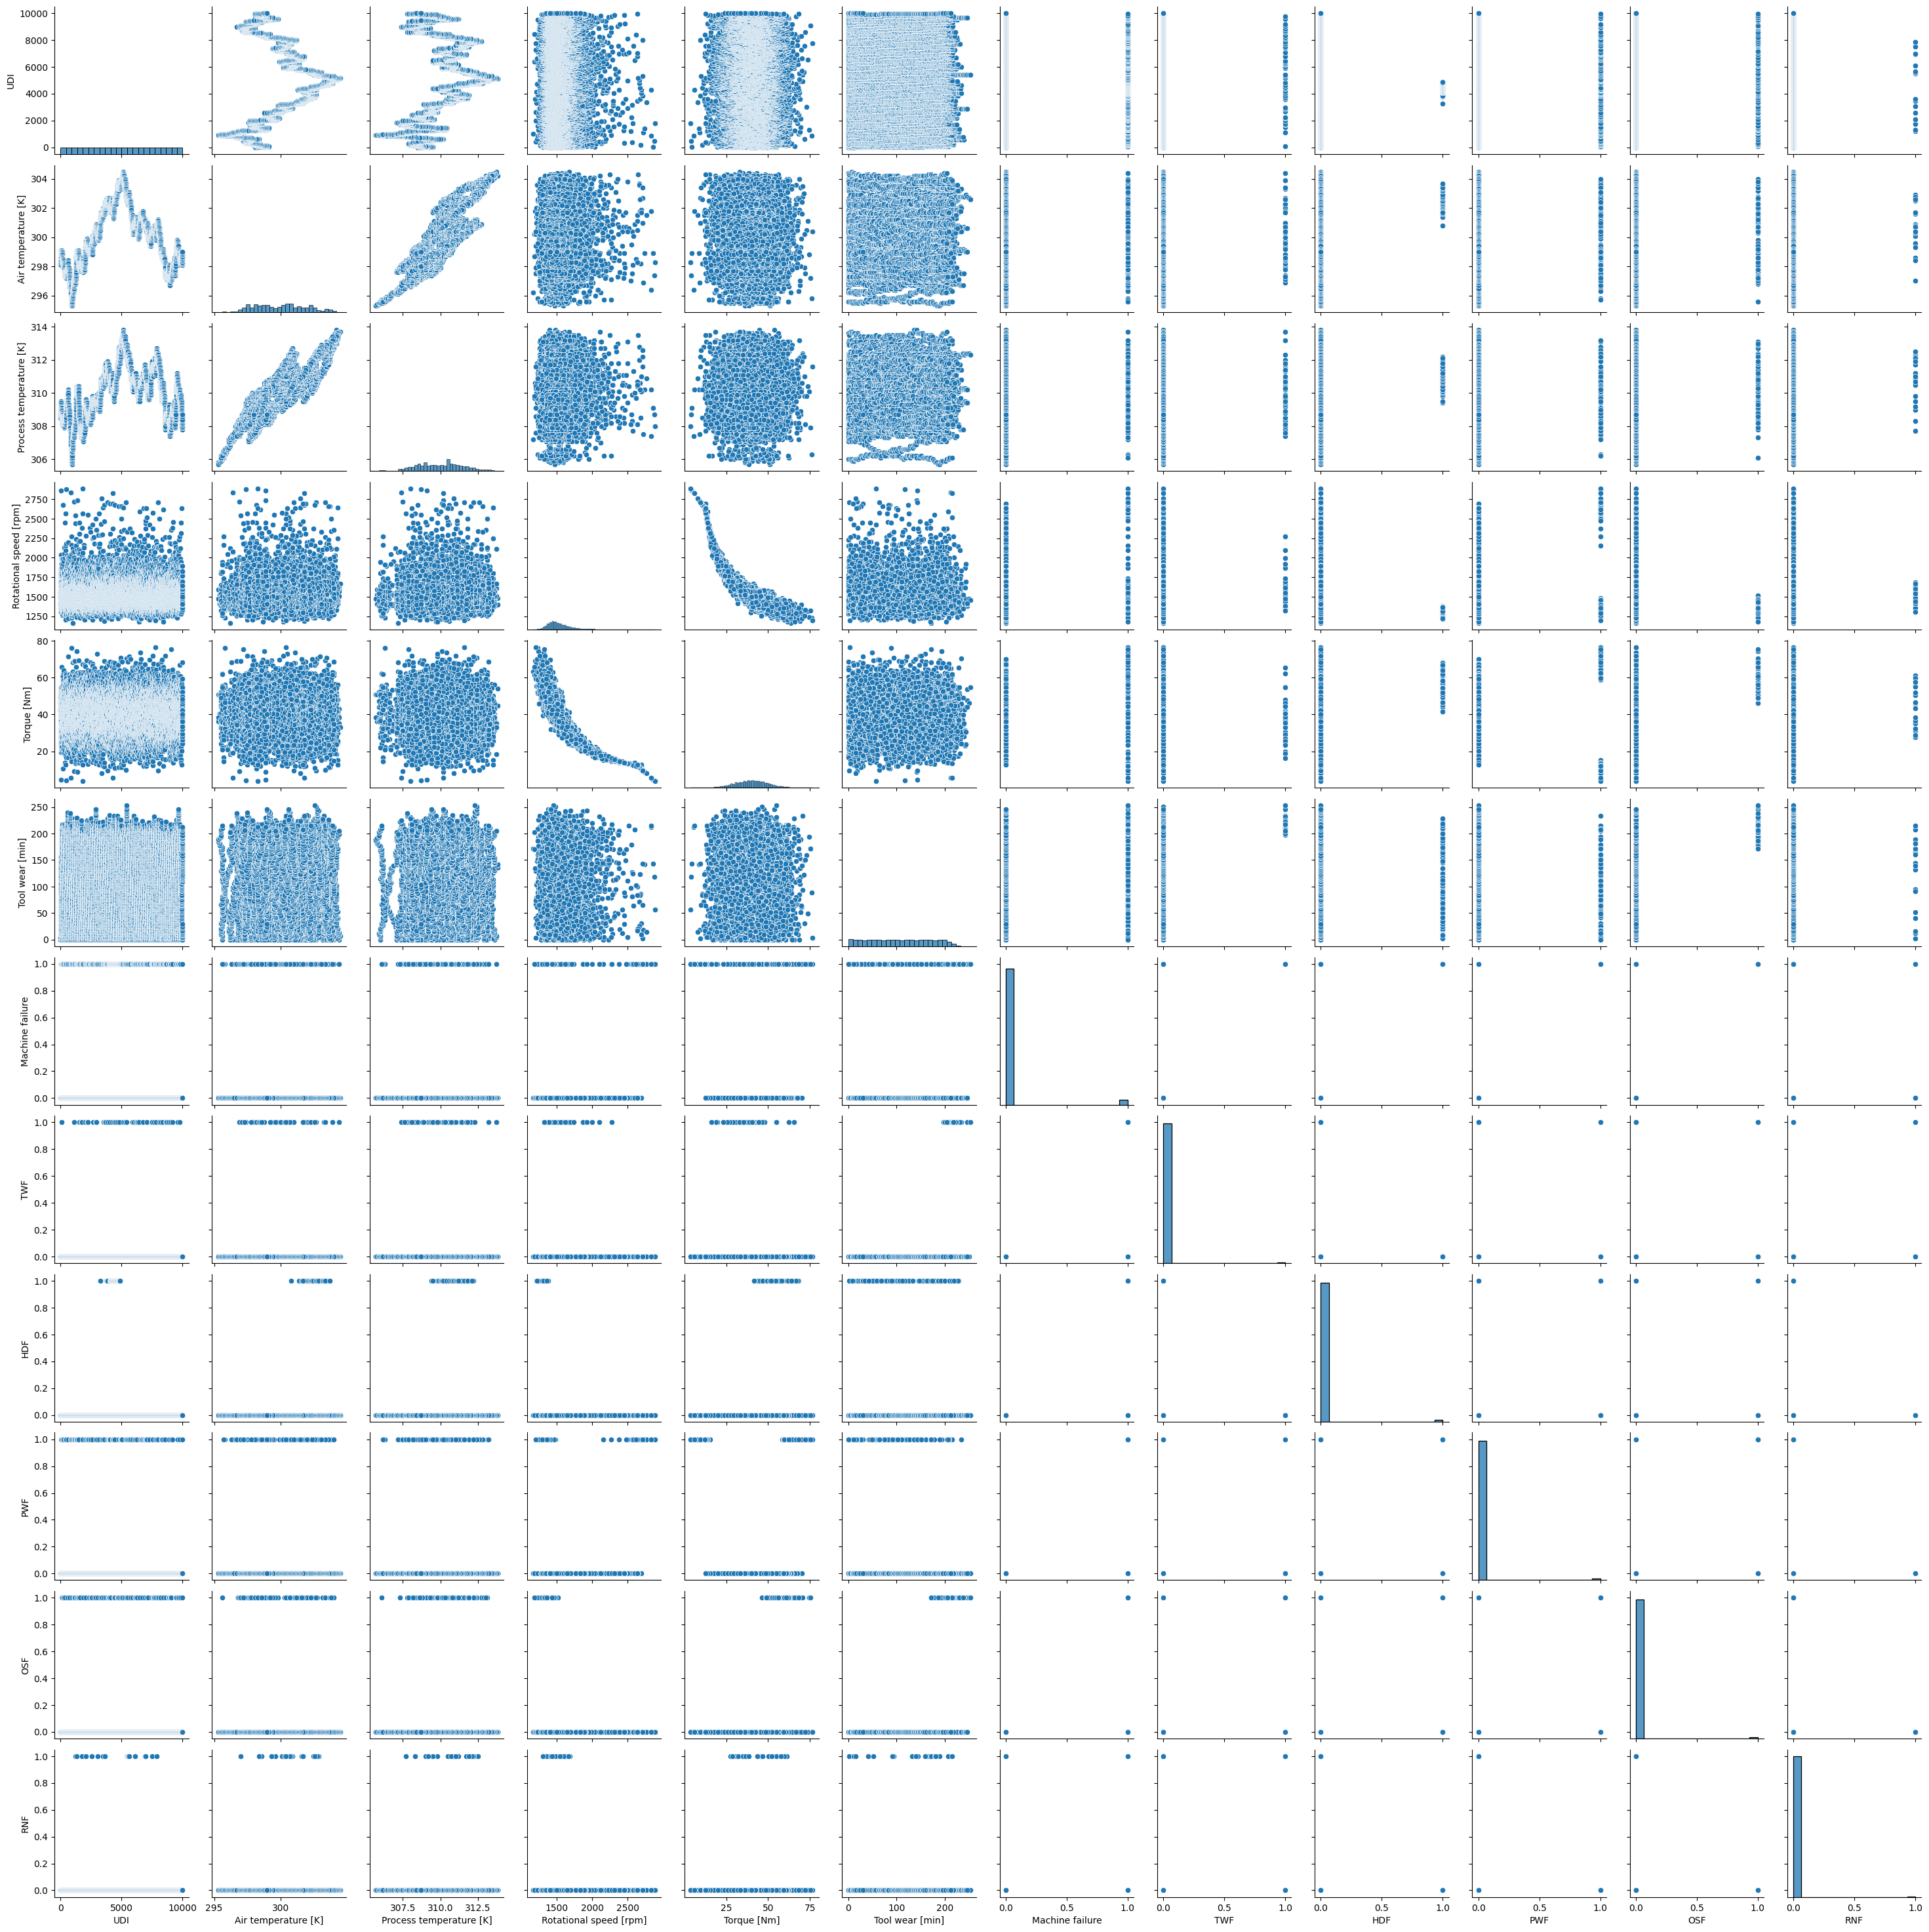

In [8]:
sns.pairplot(failure_data)

In [9]:
# Define the exact logical order
order_mapping = {'L': 0, 'M': 1, 'H': 2}

# Apply the mapping
failure_data['Type'] = failure_data['Type'].map(order_mapping)

In [10]:
failure_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  int64  
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(10

In [11]:
clean_data = failure_data.drop(['UDI', 'Product ID'], axis =  1)

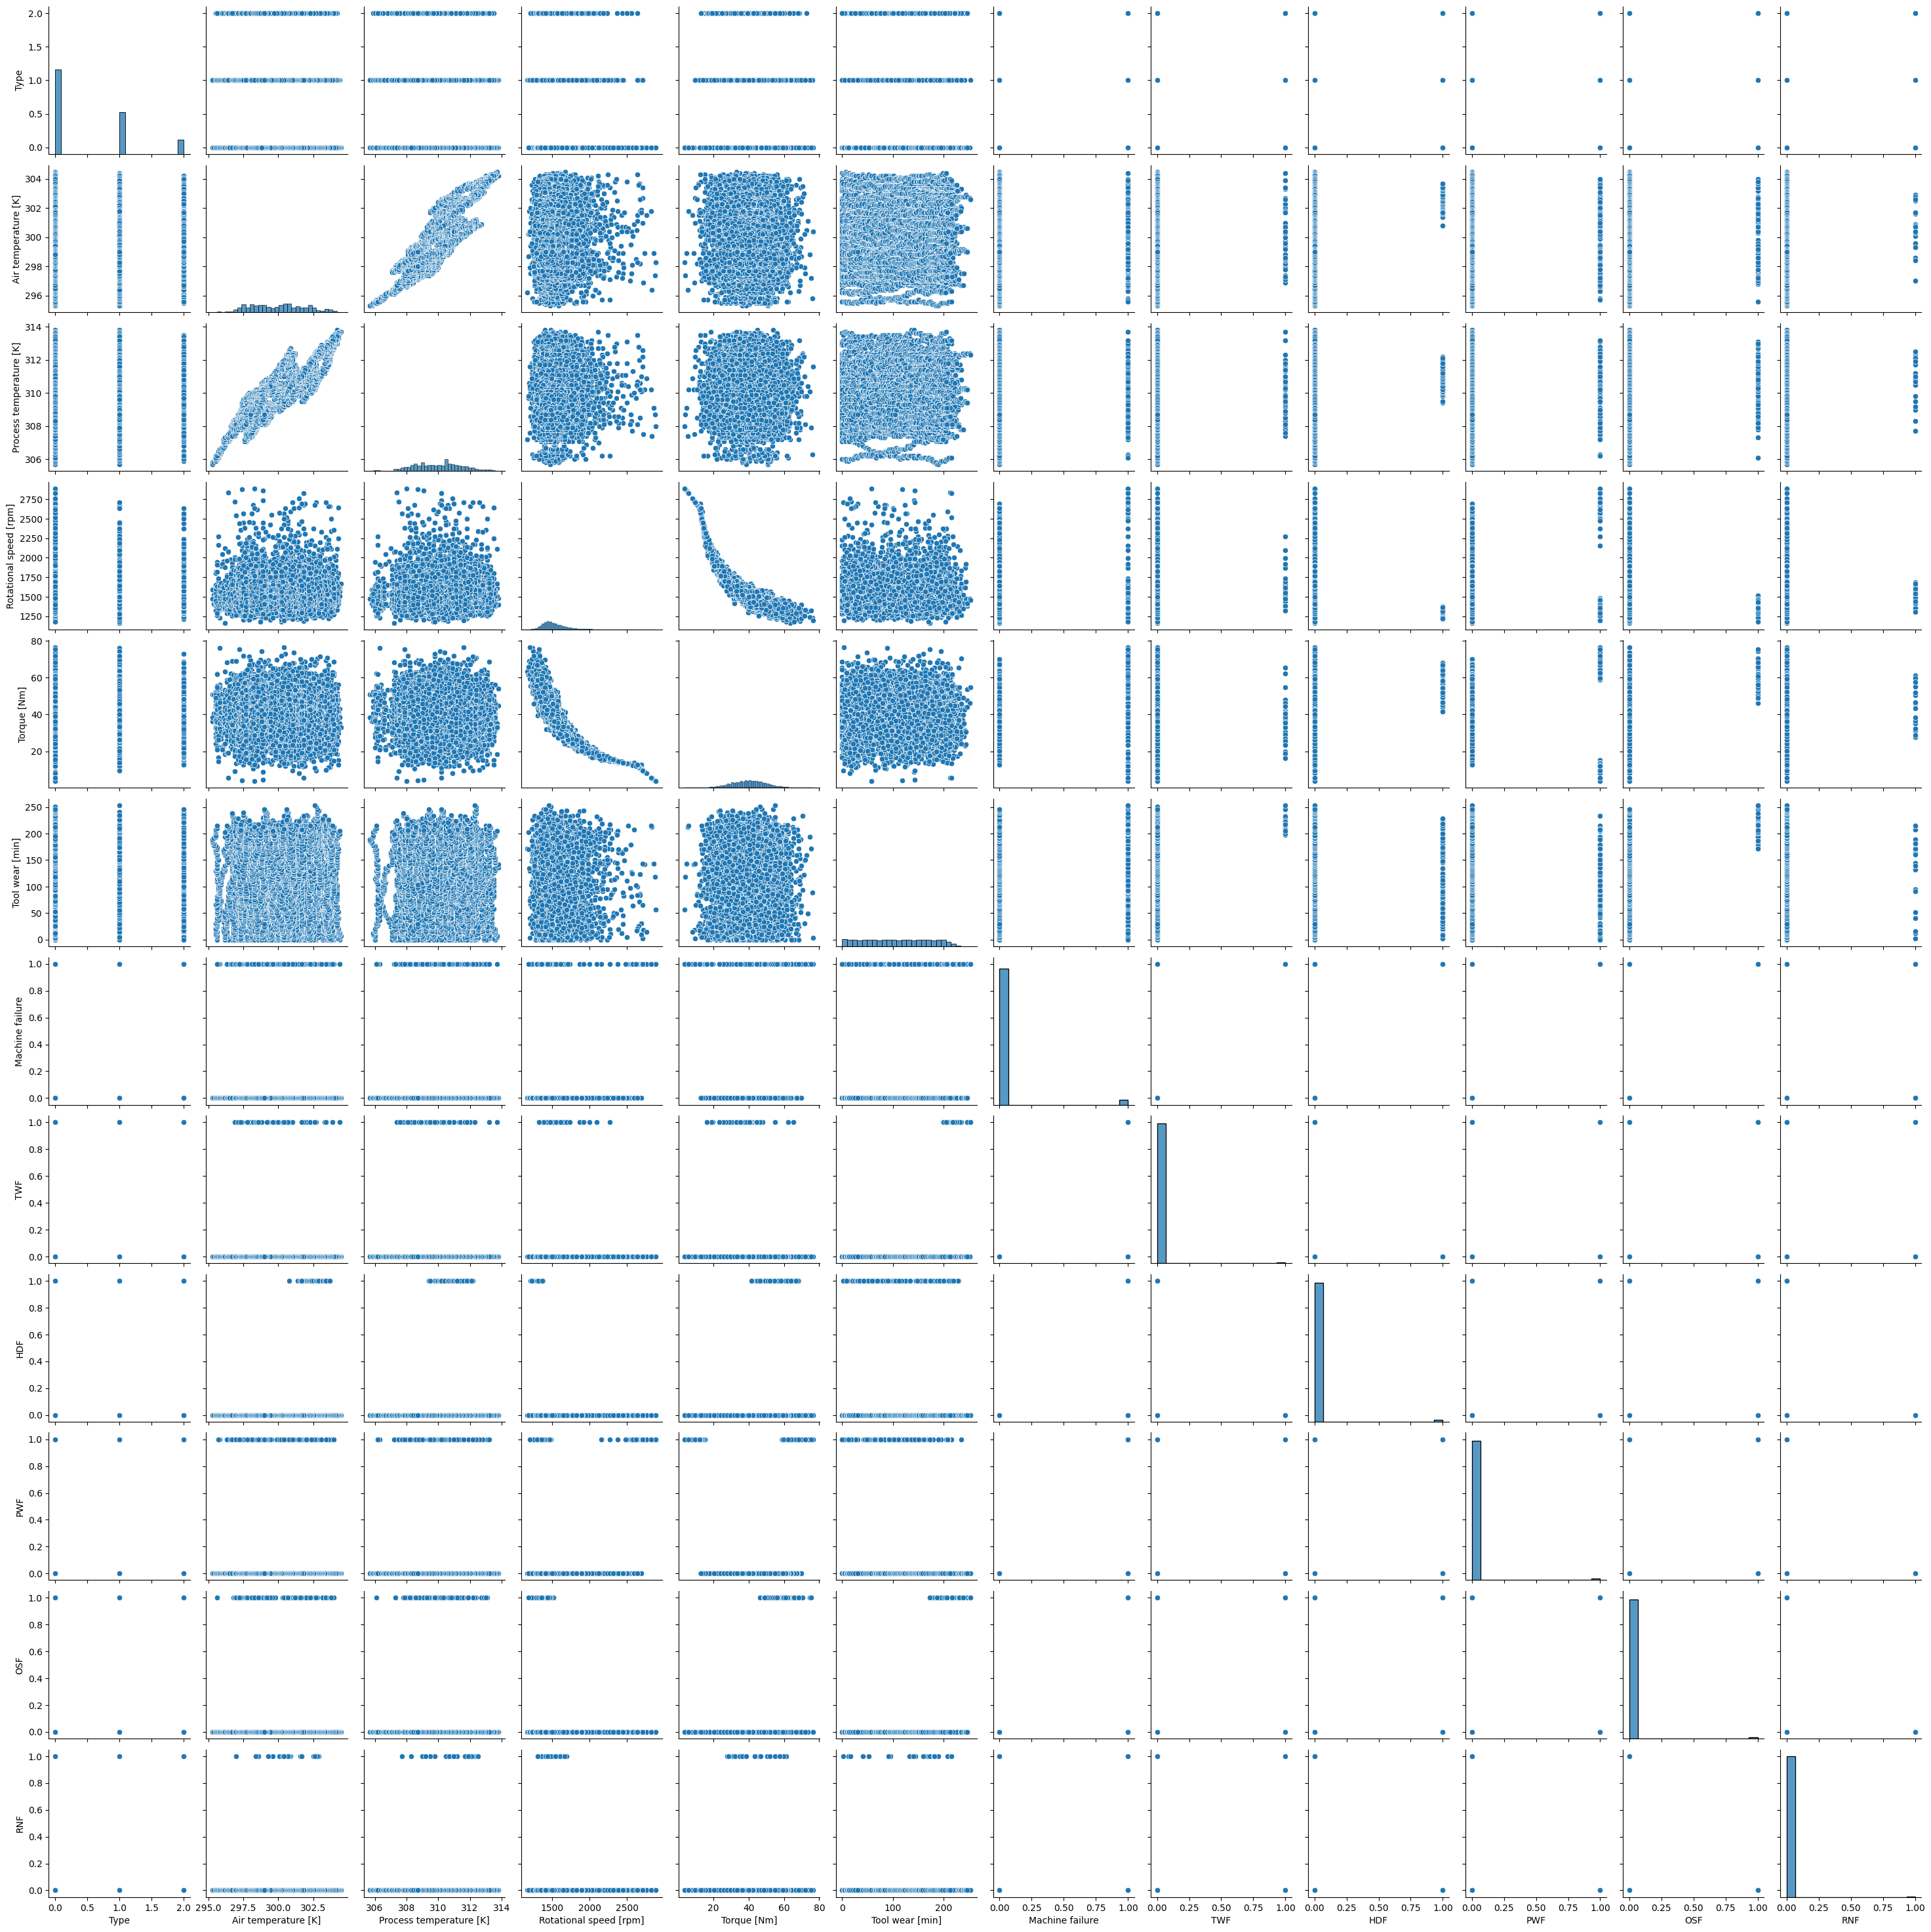

In [12]:
sns.pairplot(clean_data)
plt.show()

In [13]:

# Assuming 'df' is your DataFrame and 'target' is your column name to predict
X = clean_data.drop(columns=['Machine failure'])
y = clean_data['Machine failure']

# 1. Quick Model-Based Importance (Works best if data is already encoded)
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'RF_Importance': rf.feature_importances_
}).sort_values(by='RF_Importance', ascending=False)

print(importance_df)

                    Feature  RF_Importance
7                       HDF       0.298904
9                       OSF       0.220511
8                       PWF       0.179895
6                       TWF       0.115704
4               Torque [Nm]       0.071351
3    Rotational speed [rpm]       0.047372
5           Tool wear [min]       0.031053
1       Air temperature [K]       0.017785
2   Process temperature [K]       0.013689
0                      Type       0.003465
10                      RNF       0.000269


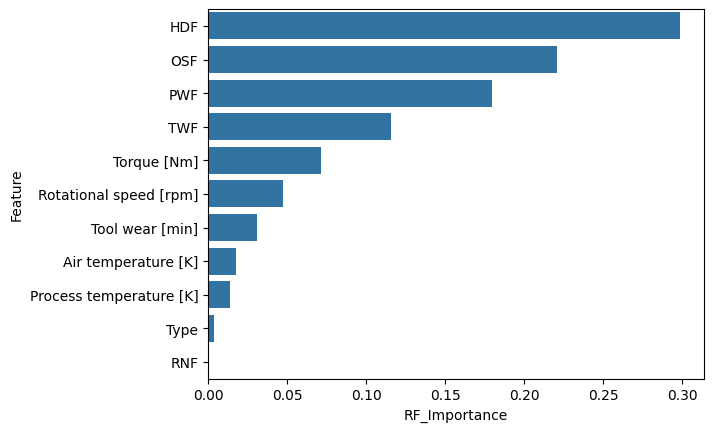

In [14]:
sns.barplot(
    y="Feature",
    x="RF_Importance",
    data=importance_df
)

plt.show()

In [15]:
clean_data['Temperature difference'] = clean_data['Process temperature [K]'] - clean_data['Air temperature [K]']
clean_data.drop(['Process temperature [K]', 'Air temperature [K]'], axis= 1, inplace= True)
clean_data.sample(5)

,Type,Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Temperature difference
1859,0,1355,45.8,60,0,0,0,0,0,0,9.6
2507,2,1410,47.1,9,0,0,0,0,0,0,9.9
9365,1,1254,55.8,65,0,0,0,0,0,0,10.6
5354,0,1462,37.5,118,0,0,0,0,0,0,9.2
8852,0,1575,39.9,12,0,0,0,0,0,0,11.2


In [16]:
clean_data['Power estimation'] = clean_data['Rotational speed [rpm]']* clean_data['Torque [Nm]']
clean_data.drop(['Rotational speed [rpm]', 'Torque [Nm]'], axis= 1, inplace= True)
clean_data.sample(5)

,Type,Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF,Temperature difference,Power estimation
6763,1,6,0,0,0,0,0,0,9.4,47223.0
7030,0,69,0,0,0,0,0,0,10.1,48375.6
7206,0,89,0,0,0,0,0,0,9.9,75618.3
7354,1,35,0,0,0,0,0,0,10.6,68163.3
3425,1,157,0,0,0,0,0,0,9.0,54370.5


In [17]:
# Assuming 'df' is your DataFrame and 'target' is your column name to predict
X = clean_data.drop(columns=['Machine failure', 'Type', 'RNF'])
y = clean_data['Machine failure']

# 1. Quick Model-Based Importance (Works best if data is already encoded)
rf = RandomForestClassifier(random_state=42)
rf.fit(X, y)

importance_df = pd.DataFrame({
    'Feature': X.columns,
    'RF_Importance': rf.feature_importances_
}).sort_values(by='RF_Importance', ascending=False)

print(importance_df)

                  Feature  RF_Importance
2                     HDF       0.304873
4                     OSF       0.235819
6        Power estimation       0.153446
3                     PWF       0.140822
1                     TWF       0.122053
0         Tool wear [min]       0.023522
5  Temperature difference       0.019465


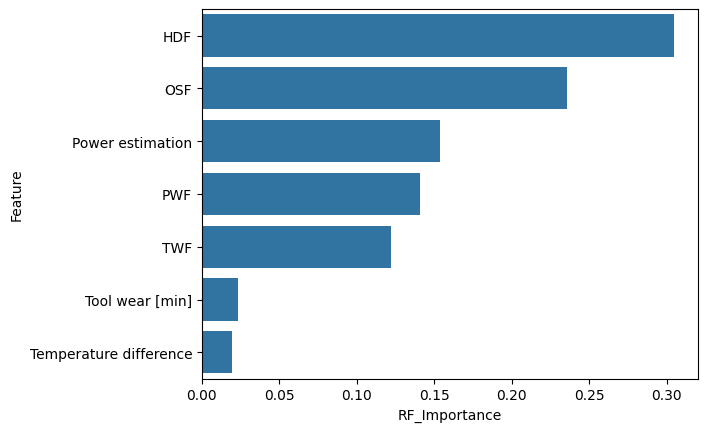

In [18]:
sns.barplot(
    y="Feature",
    x="RF_Importance",
    data=importance_df
)

plt.show()

In [19]:
# --- 1. Prepare your Data ---
# (Assuming 'df' contains your 7 engineered columns and 'Target' is your failure flag)
X = clean_data[['HDF', 'OSF', 'Power estimation', 'PWF', 'TWF', 'Tool wear [min]', 'Temperature difference']]
y = clean_data['Machine failure']  # Replace 'Target' with your actual label column name



In [24]:
# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)


In [26]:
# --- 2. Train the Model ---
model = RandomForestClassifier()
model.fit(X_train, y_train)


RandomForestClassifier()

In [27]:
# --- 3. Generate Classification Results ---
# Get hard class predictions (0 or 1)
y_pred = model.predict(X_test)

# Get probability scores (useful for adjusting thresholds later)
y_prob = model.predict_proba(X_test)[:, 1]


In [28]:
# --- 4. Print the Performance Metrics ---
print("=== CLASSIFICATION RESULTS ===")
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")

print("=== DETAILED REPORT ===")
print(classification_report(y_test, y_pred, target_names=['No Failure', 'Failure']))

=== CLASSIFICATION RESULTS ===
Overall Accuracy: 0.9993

=== DETAILED REPORT ===
              precision    recall  f1-score   support

  No Failure       1.00      1.00      1.00      2899
     Failure       1.00      0.98      0.99       101

    accuracy                           1.00      3000
   macro avg       1.00      0.99      0.99      3000
weighted avg       1.00      1.00      1.00      3000

